<a href="https://colab.research.google.com/github/MetaSeng/Practical-Applications-in-Machine-Learning/blob/main/Student_performance_predictions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/student_exam_scores.csv")

In [3]:
df

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3
...,...,...,...,...,...,...
195,S196,10.5,5.4,94.0,87,42.7
196,S197,7.1,6.1,85.1,92,40.4
197,S198,1.6,6.9,63.8,76,28.2
198,S199,12.0,7.3,50.5,58,42.0


In [5]:
df.isnull().sum()

,0
student_id,0
hours_studied,0
sleep_hours,0
attendance_percent,0
previous_scores,0
exam_score,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    object 
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 9.5+ KB


In [9]:
df.describe()

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


from matplotlib import pyplot as plt
_df_0['hours_studied'].plot(kind='hist', bins=20, title='hours_studied')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['sleep_hours'].plot(kind='hist', bins=20, title='sleep_hours')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['attendance_percent'].plot(kind='hist', bins=20, title='attendance_percent')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['previous_scores'].plot(kind='hist', bins=20, title='previous_scores')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_4.plot(kind='scatter', x='hours_studied', y='sleep_hours', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

... (3 outputs left out)

from matplotlib import pyplot as plt
_df_8['hours_studied'].plot(kind='line', figsize=(8, 4), title='hours_studied')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_9['sleep_hours'].plot(kind='line', figsize=(8, 4), title='sleep_hours')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_10['attendance_percent'].plot(kind='line', figsize=(8, 4), title='attendance_percent')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_11['previous_scores'].plot(kind='line', figsize=(8, 4), title='previous_scores')
plt.gca().spines[['top', 'right']].set_visible(False)

In [8]:
df.shape

(200, 6)

Text(0, 0.5, 'Result of exam')

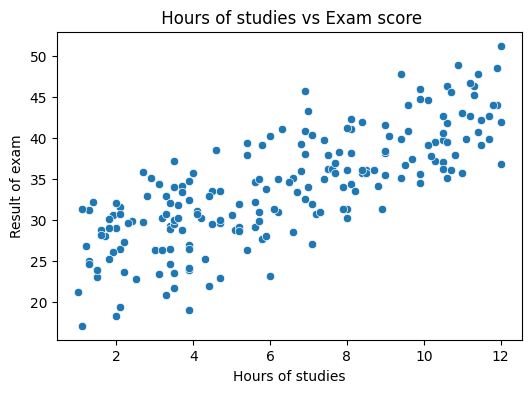

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure (figsize=(6,4))
sns.scatterplot( x = df['hours_studied'], y = df['exam_score'])
plt.title(" Hours of studies vs Exam score")
plt.xlabel("Hours of studies")
plt.ylabel("Result of exam")

Text(0, 0.5, 'Exam score')

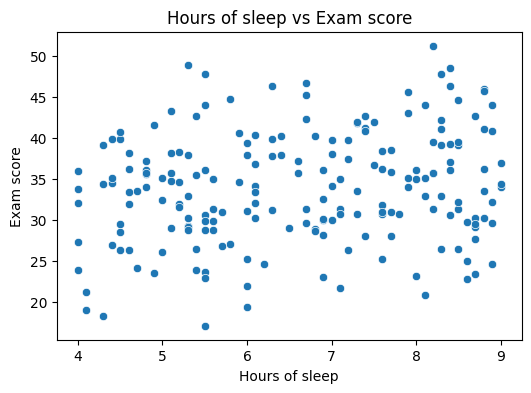

In [15]:
# Sleep vs exam score
plt.figure(figsize = (6,4))
plt.title("Hours of sleep vs Exam score")
sns.scatterplot(x = df['sleep_hours'], y = df['exam_score'])
plt.xlabel("Hours of sleep")
plt.ylabel("Exam score")

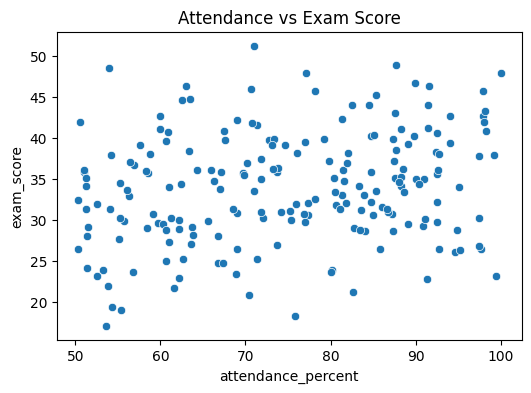

Correlation: 0.22571260459020467


In [16]:
# Scatter plot for attendance vs exam score
plt.figure(figsize=(6,4))
sns.scatterplot(x=df["attendance_percent"], y=df["exam_score"])
plt.title("Attendance vs Exam Score")
plt.show()

# Correlation
correlation_attendance = df["attendance_percent"].corr(df["exam_score"])
print("Correlation:", correlation_attendance)

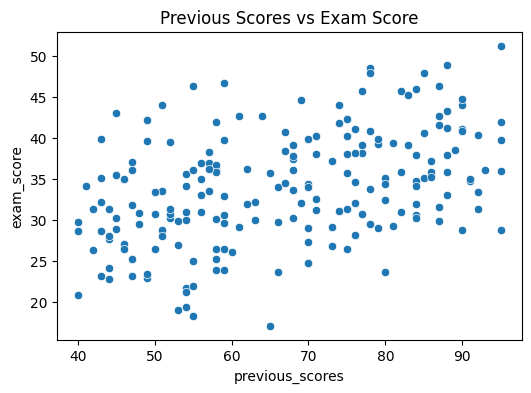

Correlation: 0.43110471124797906


In [17]:
# Scatter plot for previous scores vs exam score
plt.figure(figsize=(6,4))
sns.scatterplot(x=df["previous_scores"], y=df["exam_score"])
plt.title("Previous Scores vs Exam Score")
plt.show()

# Correlation
correlation_previous = df["previous_scores"].corr(df["exam_score"])
print("Correlation:", correlation_previous)

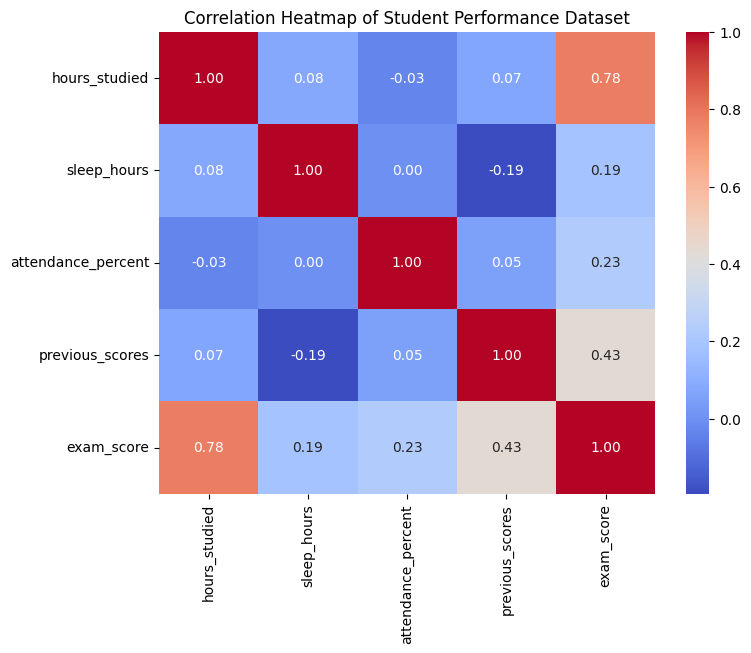

In [18]:
plt.figure(figsize=(8,6))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Student Performance Dataset")
plt.show()

The analysis confirms that study time is the most controllable and impactful factor for exam performance, while factors like attendance and sleep show weaker relationships. This suggests students should prioritize dedicated study hours for optimal academic outcomes, though a balanced approach considering all factors remains important.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Features (independent variables) — adjust as needed
X = df[["hours_studied", "sleep_hours", "attendance_percent", "previous_scores"]]
# Target (dependent variable)
y = df["exam_score"]

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

#Predictions
y_pred = model.predict(X_test)

# Model evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Coefficients: ", model.coef_)
print("Intercept: ", model.intercept_)
print("Root mean squared error: ", rmse)
print("R2 Score: ", r2)

Model Coefficients:  [1.54934126 0.88415643 0.10894946 0.18303355]
Intercept:  -2.204963905836877
Root mean squared error:  2.785997607433121
R2 Score:  0.8537447137159516


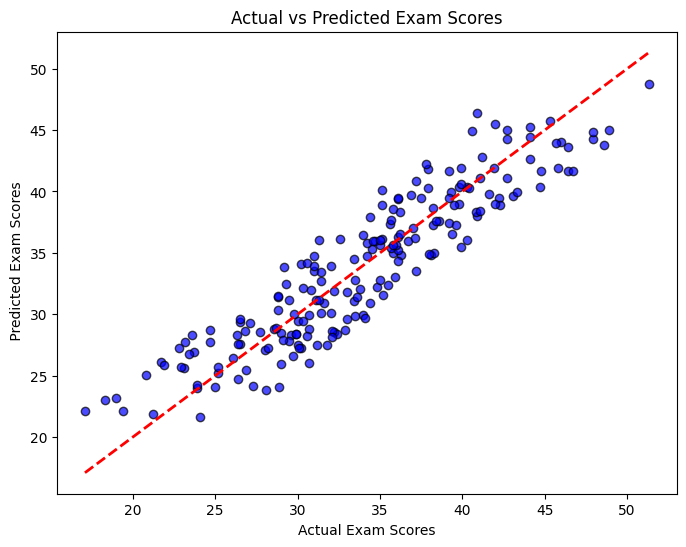

In [32]:
import matplotlib.pyplot as plt

# Predict using the trained model
y_pred = model.predict(X)

#Scatter plot of actual vs predicted
plt.figure(figsize = (8,6))
plt.title("Actual vs Predicted Exam Scores")
plt.scatter(y, y_pred, alpha = 0.7, color = "blue", edgecolor = "k")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2) # perfect prediction line
plt.xlabel("Actual Exam Scores")
plt.ylabel(" Predicted Exam Scores")
plt.show()